# Демо-экзамен по курсу "Прикладной анализ данных". Вариант 3

Выполнил: Троян Денис Игоревич

МИФИ + Скиллфэктори, Машинное обучение, Прикладная математика и информатика


Вставьте ниже скриншот с результатом вашего решения в Leaderboard на Kaggle: https://www.kaggle.com/competitions/butterflies-classification



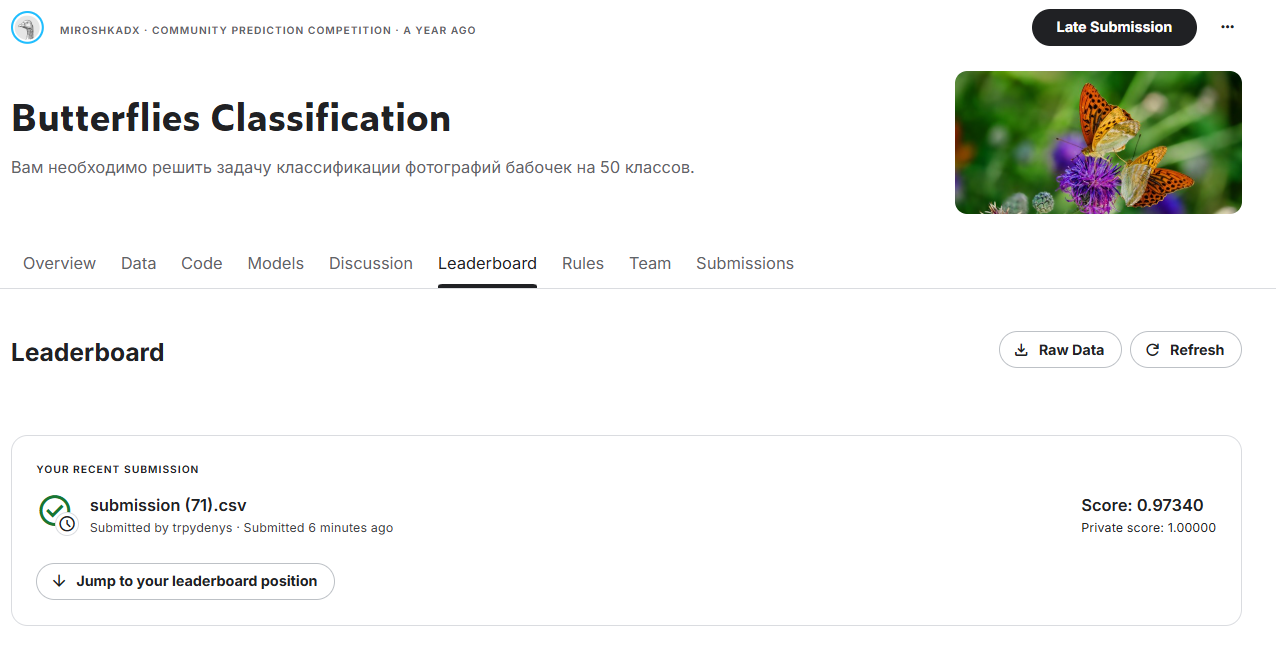

## 1. Описание задачи и данные

Вам необходимо решить задачу классификации фотографий бабочек на 50 классов. Каждая фотография представляет из себя цветное изображение размера 224×224.

Вам предоставлены два набора данных:

Папка train содержит в себе 50 папок, разбитых на классы.
Папка test содержит в себе 250 фотографий, которые вам необходимо классифицировать.
Решение оценивается метрикой accuracy.
Ссылка на соревнование и на данные: https://www.kaggle.com/competitions/butterflies-classification

In [2]:
# Устанавливаем необходимые библиотеки
!pip install opendatasets --quiet

In [16]:
# Импортируем необходимые библиотеки
import opendatasets as od

from tqdm import tqdm
import random
import os
import numpy as np
import torch
import copy

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import seaborn as sns

from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms

import torch.nn as nn
import torchvision.models as models

In [4]:
# Скачиваем датасет
# !!! ЗАГРУЗИТЬ в папку Файлы файл kaggle.json
url = 'https://www.kaggle.com/competitions/butterflies-classification'
od.download(url)

100%|██████████| 132M/132M [00:00<00:00, 154MB/s]



Extracting archive ./butterflies-classification/butterflies-classification.zip to ./butterflies-classification


In [5]:
# Фиксируем seed для воспроизводимости
def seed_everything(seed=42):
    # 1. Фиксация встроенного генератора случайных чисел Python
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

    # 2. Фиксация генератора NumPy
    np.random.seed(seed)

    # 3. Фиксация генераторов PyTorch
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # 4. Настройка детерминизма для алгоритмов свертки CUDA
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Вызов функции
seed_everything(42)

## 1. Провести предварительное исследование данных

- сколько у вас есть изображений? Все ли они одного разрешения? Какой баланс классов в данных?
- какие есть особенности датасета?
- если необходимо произвести очистку и предварительную обработку данных.


--- Запуск предварительного исследования данных ---
Сканирование папки train...


100%|██████████| 50/50 [00:00<00:00, 129.50it/s]
/tmp/ipykernel_646/2626682824.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")



1. Количество изображений:
   - В обучающей выборке (train): 4955
   - В тестовой выборке (test): 250
   - Найдено поврежденных файлов: 0

2. Проверка разрешений сторон:
   - Все изображения имеют строго одинаковое разрешение: 224x224

3. Количество цветовых каналов:
   - RGB (3 кан.): 4955 шт.

4. Дисбаланс классов:
   - Всего уникальных классов: 50
   - Максимум картинок в одном классе: 139 (класс: 'class_37')
   - Минимум картинок в одном классе: 66 (класс: 'class_11')
   - Среднее количество картинок на класс: 99.1


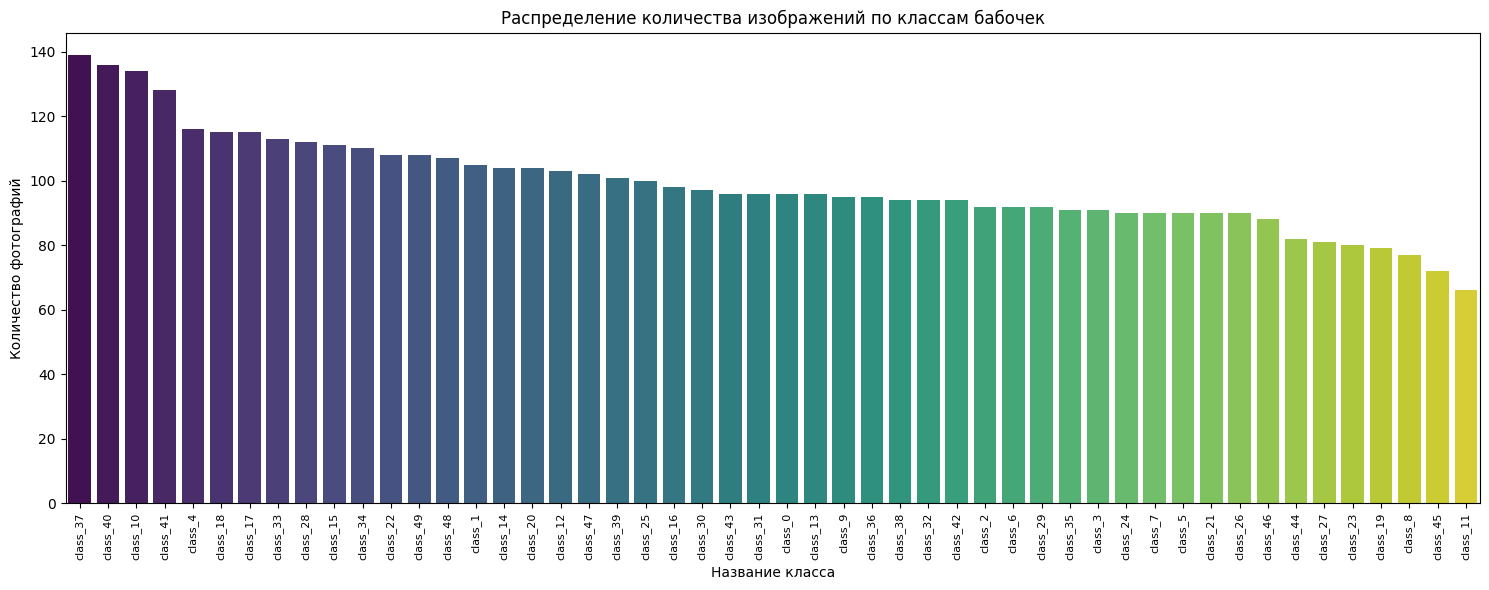

In [8]:
# Фиксируем пути к изображениям
BASE = Path("/content/butterflies-classification")
TRAIN_DIR = Path(BASE) / "train_butterflies" / "train_split"
TEST_DIR = Path(BASE) / "test_butterflies" / "valid"

# Функция для исследования данных
def run_image_eda(train_path, test_path):
    print("\n--- Запуск предварительного исследования данных ---")

    # Проверка физического существования папок после скачивания
    if not os.path.exists(train_path) or not os.path.exists(test_path):
        print(f"Ошибка: Директории не найдены. Проверьте содержимое папки {DATASET_NAME}")
        return None, None

    classes = os.listdir(train_path)
    train_images_data = []
    corrupted_images = []

    print("Сканирование папки train...")
    for class_name in tqdm(classes):
        class_full_path = os.path.join(train_path, class_name)

        # Игнорируем системные скрытые файлы (.DS_Store и т.д.)
        if not os.path.isdir(class_full_path):
            continue

        for img_name in os.listdir(class_full_path):
            img_path = os.path.join(class_full_path, img_name)
            try:
                with Image.open(img_path) as img:
                    width, height = img.size
                    channels = len(img.getbands())
                    train_images_data.append({
                        "class": class_name,
                        "width": width,
                        "height": height,
                        "channels": channels,
                        "path": img_path
                    })
            except Exception as e:
                corrupted_images.append(img_path)

    # Создание датафрейма для анализа геометрии и баланса классов
    df_train = pd.DataFrame(train_images_data)

    # Сканирование тестовой выборки (все файлы внутри test)
    test_images = [
        os.path.join(test_path, f)
        for f in os.listdir(test_path)
        if os.path.isfile(os.path.join(test_path, f)) and not f.startswith('.')
    ]

    # --- ВЫВОД РЕЗУЛЬТАТОВ АНАЛИЗА ---

    # 1. Подсчет количества изображений
    total_train = len(df_train)
    total_test = len(test_images)
    print(f"\n1. Количество изображений:")
    print(f"   - В обучающей выборке (train): {total_train}")
    print(f"   - В тестовой выборке (test): {total_test}")
    print(f"   - Найдено поврежденных файлов: {len(corrupted_images)}")

    # 2. Проверка разрешений картинок
    unique_sizes = df_train.groupby(['width', 'height']).size().reset_index(name='count')
    print(f"\n2. Проверка разрешений сторон:")
    if len(unique_sizes) == 1:
        w, h = unique_sizes.iloc[0]['width'], unique_sizes.iloc[0]['height']
        print(f"   - Все изображения имеют строго одинаковое разрешение: {w}x{h}")
    else:
        print(f"   - Внимание! Обнаружены отклонения в размерах картинок:")
        print(unique_sizes.to_string(index=False))

    # 3. Анализ цветовых каналов
    unique_channels = df_train['channels'].value_counts()
    print(f"\n3. Количество цветовых каналов:")
    for ch, count in unique_channels.items():
        ch_type = "RGB" if ch == 3 else ("RGBA" if ch == 4 else "Grayscale/Другое")
        print(f"   - {ch_type} ({ch} кан.): {count} шт.")

    # 4. Анализ баланса классов
    class_counts = df_train['class'].value_counts()
    print(f"\n4. Дисбаланс классов:")
    print(f"   - Всего уникальных классов: {len(class_counts)}")
    print(f"   - Максимум картинок в одном классе: {class_counts.max()} (класс: '{class_counts.idxmax()}')")
    print(f"   - Минимум картинок в одном классе: {class_counts.min()} (класс: '{class_counts.idxmin()}')")
    print(f"   - Среднее количество картинок на класс: {class_counts.mean():.1f}")

    # Отрисовка распределения классов
    plt.figure(figsize=(15, 6))
    sns.barplot(x=class_counts.index, y=class_counts.values, palette="viridis")
    plt.xticks(rotation=90, fontsize=8)
    plt.title("Распределение количества изображений по классам бабочек")
    plt.xlabel("Название класса")
    plt.ylabel("Количество фотографий")
    plt.tight_layout()
    plt.savefig(os.path.join(BASE, "class_distribution.png"))
    plt.show()

    return df_train, corrupted_images

# Автоматический запуск анализа после скачивания данных
df_train, corrupted = run_image_eda(TRAIN_DIR, TEST_DIR)

# Вывод:

### Наличие дисбаланса классов:

В данных присутствует умеренный, но заметный дисбаланс. Разница между самым большим и самым маленьким классом составляет более чем 2 раза. Максимальный класс: class_37 содержит 139 фотографий. Минимальный класс: class_11 содержит всего 66 фотографий. Среднее значение: 99.1 изображений на один класс.

Характер распределения: График показывает плавное убывание количества примеров от класса к классу (без критических провалов до единичных экземпляров). Однако, если модель не сбалансировать, она будет лучше распознавать бабочек из class_37 и чаще ошибаться на бабочках из class_11.

## 2. Подготовить данные для обучения

- Создать тренировочную и тестовую подвыборки для обучения и тестирования работы моделей
- Создать класс на фреймворке `PyTorch` для создания датасета
- Создать `loader` для передачи данных в модель нейронной сети

In [17]:
# Аугментация для тренировочных данных: защищает модель от переобучения
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),               # Приведение к единому размеру 224x224
    transforms.RandomHorizontalFlip(p=0.5),      # Случайный поворот по горизонтали
    transforms.RandomRotation(degrees=15),       # Случайный поворот на угол до 15 градусов
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1), # Искажение цветов
    transforms.ToTensor(),                       # Перевод картинки в тензор PyTorch (0-1)
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Стандартизация ImageNet
])

# Трансформации для валидации/теста: только приведение формы и нормализация
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),               # Приведение к единому размеру 224x224
    transforms.ToTensor(),                       # Перевод в тензор PyTorch
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # Стандартизация ImageNet
])


# Кастомный класс датасета

class MyDataset(Dataset):
    def __init__(self, data_dir, transform=None, is_train=True):
        self.data_dir = data_dir
        self.transform = transform
        self.is_train = is_train
        self.images = []                         # Список путей к изображениям
        self.labels = []                         # Список меток классов или имен файлов

        if is_train:
            # Сбор папок-классов и сопоставление их с ID (0, 1, 2...)
            self.classes = sorted([d.name for d in data_dir.iterdir() if d.is_dir()])
            self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}

            # Чтение файлов из папок каждого класса
            for cls in self.classes:
                cls_path = data_dir / cls
                img_files = list(cls_path.glob("*.jpg")) + list(cls_path.glob("*.png"))

                for img_path in img_files:
                    self.images.append(str(img_path))
                    self.labels.append(self.class_to_idx[cls]) # Сохраняем ID класса
        else:
            # Для тестовых данных: сбор всех картинок из корня папки
            img_files = list(data_dir.glob("*.jpg")) + list(data_dir.glob("*.png"))

            for img_path in img_files:
                self.images.append(str(img_path))
                self.labels.append(img_path.name) # Сохраняем имя файла вместо ID

    def __len__(self):
        # Возвращает общее количество картинок в датасете
        return len(self.images)

    def __getitem__(self, idx):
        # Загрузка и обработка одного элемента по индексу
        img_path = self.images[idx]
        image = Image.open(img_path).convert('RGB') # Чтение в формате RGB

        if self.is_train:
            label = self.labels[idx]
            if self.transform:
                image = self.transform(image)    # Применение тренировочных трансформаций
            return image, label
        else:
            img_name = self.labels[idx]
            if self.transform:
                image = self.transform(image)    # Применение валидационных трансформаций
            return image, img_name


# Инициализация путей и создание объектов датасета

BASE = Path("/content/butterflies-classification")
TRAIN_DIR = Path(BASE) / "train_butterflies" / "train_split"
TEST_DIR = Path(BASE) / "test_butterflies" / "valid"

# Создание экземпляров кастомного датасета
train_data = MyDataset(TRAIN_DIR, transform=train_transform, is_train=True)
test_data = MyDataset(TEST_DIR, transform=val_transform, is_train=False)

# Расчет пропорций для разбиения (80% на обучение, 20% на валидацию)
dataset_size = len(train_data)
train_size = int(0.8 * dataset_size)
val_size = dataset_size - train_size

print(f"Размер датасета: {dataset_size}")
print(f"Тренировочная часть: {train_size}")
print(f"Валидационная часть: {val_size}")

# Случайное разбиение тренировочного датасета
train_dataset_raw, valid_dataset_raw = random_split(
    train_data, [train_size, val_size], generator=torch.Generator().manual_seed(42)
)

# Назначение валидационных трансформаций для проверочной выборки
valid_data = copy.deepcopy(valid_dataset_raw)
valid_data.dataset.transform = val_transform

train_data = train_dataset_raw
train_data.dataset.transform = train_transform
# Создание загрузчиков данных (DataLoaders)

BATCH_SIZE = 32                                  # Размер пакета данных (батча)
NUM_WORKERS = 2                                  # Количество параллельных потоков CPU

# Загрузчик для обучения: данные перемешиваются каждый раз
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,                                # Перемешивание обязательно для обучения
    num_workers=NUM_WORKERS,
    pin_memory=True,                             # Ускоряет передачу тензоров на GPU
    drop_last=False
)

# Загрузчик для валидации: данные не перемешиваются
valid_loader = DataLoader(
    valid_data,
    batch_size=BATCH_SIZE,
    shuffle=False,                               # Порядок картинок менять не нужно
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)

# Загрузчик для финального тестирования: данные не перемешиваются
test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,                               # Порядок картинок менять не нужно
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)


Размер датасета: 4955
Тренировочная часть: 3964
Валидационная часть: 991


## 3. Реализация модели

- создать класс для модели
- создать функцию для обучения модели
- создать функцию для валидации модели

In [18]:
# Кастомный класс модели

class RSNAModel(nn.Module):
    def __init__(self, num_classes=50, model_name='resnet50'):
        super(RSNAModel, self).__init__()

        # Вариант 1: Использование архитектуры ResNet50
        if model_name == 'resnet50':
            # Загрузка предобученной на ImageNet модели ResNet50
            self.backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
            # Получение размерности выходных признаков перед полносвязным слоем
            in_features = self.backbone.fc.in_features
            # Замена оригинального классификатора на кастомную структуру с Dropout и ReLU
            self.backbone.fc = nn.Sequential(
                nn.Dropout(0.3),                 # Защита от переобучения (зануление 30% связей)
                nn.Linear(in_features, 256),    # Промежуточный скрытый слой на 256 нейронов
                nn.ReLU(),                       # Функция активации для нелинейности
                nn.Dropout(0.3),                 # Повторный Dropout для регуляризации
                nn.Linear(256, num_classes)     # Финальный слой классификации под num_classes
            )

        # Вариант 2: Использование архитектуры EfficientNet-B0
        elif model_name == 'efficientnet':
            # Загрузка предобученной модели EfficientNet_B0
            self.backbone = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
            # Получение размерности признаков из оригинального классификатора
            in_features = self.backbone.classifier[1].in_features
            # Замена классификатора на Dropout и один линейный слой под нужное число классов
            self.backbone.classifier = nn.Sequential(
                nn.Dropout(0.3),
                nn.Linear(in_features, num_classes)
            )

        # Вариант 3: Использование архитектуры DenseNet121
        elif model_name == 'densenet':
            # Загрузка предобученной модели DenseNet121
            self.backbone = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
            # Получение входной размерности финального классификатора
            in_features = self.backbone.classifier.in_features
            # Прямая замена классификатора на один линейный слой без скрытых слоев
            self.backbone.classifier = nn.Linear(in_features, num_classes)

        # Сохранение имени выбранной архитектуры в атрибут класса
        self.model_name = model_name

    def forward(self, x):
        # Прямой проход данных через выбранную и модифицированную нейросеть
        return self.backbone(x)


In [19]:
# Функция для обучения модели в течение одной эпохи

def train_one_epoch(model, train_dataloader, optimizer, loss_fn, epoch, device, log_wandb=True, verbose=False):
    model.train()                   # Перевод модели в режим обучения (включает Dropout, BatchNorm)
    running_loss = 0.0              # Накопитель для суммарной ошибки за эпоху
    correct = 0                     # Счетчик правильно угаданных классов
    total = 0                       # Общий счетчик обработанных изображений

    # Создание прогресс-бара, если включен подробный режим вывода (verbose)
    loop = tqdm(train_dataloader, desc=f'Epoch {epoch} Training') if verbose else train_dataloader

    # Цикл по пакетам (батчам) данных из загрузчика
    for batch_idx, (images, labels) in enumerate(loop):
        # Перенос изображений и меток на целевое устройство (например, GPU)
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()       # Сброс градиентов параметров модели перед новым шагом
        outputs = model(images)     # Прямой проход (forward pass): получение предсказаний модели
        loss = loss_fn(outputs, labels) # Вычисление функции потерь (ошибки)
        loss.backward()             # Обратный проход (backward pass): расчет градиентов
        optimizer.step()            # Обновление весов модели оптимизатором

        # Сбор метрик
        running_loss += loss.item() # Добавление ошибки текущего батча к общей сумме
        _, predicted = outputs.max(1) # Получение индексов классов с максимальной вероятностью
        total += labels.size(0)     # Прибавление размера батча к общему числу картинок
        correct += predicted.eq(labels).sum().item() # Подсчет совпавших предсказаний

        # Периодический вывод логов в консоль каждые 50 батчей
        if verbose and batch_idx % 50 == 0:
            print(f'Epoch: {epoch} | Batch: {batch_idx} | Loss: {loss.item():.4f}')

    # Расчет финальных метрик за всю эпоху обучения
    avg_loss = running_loss / len(train_dataloader) # Средняя ошибка на один батч
    accuracy = 100.0 * correct / total             # Точность (Accuracy) в процентах

    return avg_loss, accuracy


# Функция для валидации модели на одной эпохе

@torch.no_grad() # Отключение расчета градиентов для экономии памяти и ускорения вычислений
def valid_one_epoch(model, valid_dataloader, loss_fn, epoch, device, log_wandb=True, verbose=False):
    model.eval()                    # Перевод модели в режим оценки (выключает Dropout, замораживает BatchNorm)
    running_loss = 0.0              # Накопитель ошибки для валидации
    correct = 0                     # Счетчик правильных ответов на валидации
    total = 0                       # Общий счетчик валидационных картинок

    # Создание прогресс-бара для валидации
    loop = tqdm(valid_dataloader, desc=f'Epoch {epoch} Validation') if verbose else valid_dataloader

    # Итерация по валидационным данным (без вычисления градиентов и шагов оптимизатора)
    for images, labels in loop:
        images, labels = images.to(device), labels.to(device) # Перенос на GPU
        outputs = model(images)     # Получение предсказаний
        loss = loss_fn(outputs, labels) # Расчет ошибки на валидационном батче

        # Сбор метрик валидации
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    # Расчет средних метрик по итогам проверки
    avg_loss = running_loss / len(valid_dataloader) # Средняя ошибка на валидации
    accuracy = 100.0 * correct / total             # Точность на валидации в процентах

    return avg_loss, accuracy


## 4. Обучение модели
*   Определить необходимые параметры для обучения модели (learning rate, optimizer, loss function, etc)
*   Реализовать процесс обучения модели
*   Оценить эффективность работы модели



Используемое устройство: cuda
НАЧАЛО ОБУЧЕНИЯ

Epoch 1/10
------------------------------


Epoch 1 Training:   1%|          | 1/124 [00:00<01:54,  1.08it/s]

Epoch: 1 | Batch: 0 | Loss: 3.9081


Epoch 1 Training:  41%|████      | 51/124 [00:23<00:31,  2.30it/s]

Epoch: 1 | Batch: 50 | Loss: 2.9133


...

Epoch: 10 | Batch: 50 | Loss: 0.0258


Epoch 10 Training:  81%|████████▏ | 101/124 [00:42<00:09,  2.38it/s]

Epoch: 10 | Batch: 100 | Loss: 0.0105


Epoch 10 Validation: 100%|██████████| 31/31 [00:03<00:00,  8.11it/s]



Train Loss: 0.0946 | Train Acc: 97.48%
Val Loss: 0.2483 | Val Acc: 94.25%
LR: 0.000100
>>> Новая лучшая модель! Acc: 94.25%

Лучшая валидационная точность: 94.25%


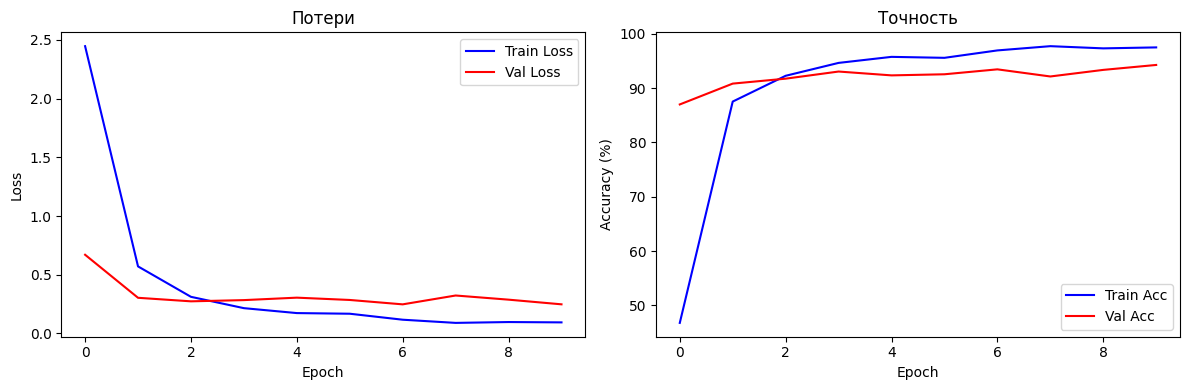

In [20]:
# Конфигурация среды и гиперпараметров

# Автоматический выбор GPU (cuda), если доступен, иначе вычисления на CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Используемое устройство: {device}")

# Определение основных констант обучения
EPOCHS = 10                  # Количество полных проходов по датасету
LEARNING_RATE = 0.0001       # Начальная скорость обучения (шаг градиентного спуска)
NUM_CLASSES = 50             # Количество целевых классов для классификации

# Создание экземпляра модели и её перенос на целевое устройство (GPU/CPU)
model = RSNAModel(num_classes=NUM_CLASSES, model_name='resnet50')
model = model.to(device)

# Инициализация функции потерь, оптимизатора и планировщика темпа обучения
criterion = nn.CrossEntropyLoss() # Функция потерь для многоклассовой классификации
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE) # Оптимизатор Adam
# Планировщик: снижает LR в 2 раза (factor=0.5), если val_loss не улучшается 3 эпохи подряд
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

# Переменные для отслеживания лучшего результата и сохранения истории метрик
best_val_acc = 0
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print("="*50)
print("НАЧАЛО ОБУЧЕНИЯ")
print("="*50)


# Главный цикл обучения (по эпохам)

for epoch in range(1, EPOCHS + 1):
    print(f"\nEpoch {epoch}/{EPOCHS}")
    print("-" * 30)

    # Шаг 1: Обучение модели на тренировочной выборке за одну эпоху
    train_loss, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion,
        epoch, device, log_wandb=False, verbose=True
    )

    # Шаг 2: Проверка качества модели на валидационной выборке
    val_loss, val_acc = valid_one_epoch(
        model, valid_loader, criterion,
        epoch, device, log_wandb=False, verbose=True
    )

    # Шаг 3: Обновление скорости обучения (LR) на основе потерь валидации
    scheduler.step(val_loss)

    # Шаг 4: Запись полученных метрик в историю эксперимента
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    # Вывод логов по итогам текущей эпохи
    print(f"\nTrain Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")
    print(f"LR: {optimizer.param_groups[0]['lr']:.6f}") # Текущее значение Learning Rate

    # Шаг 5: Сохранение весов модели, если достигнута лучшая точность на валидации
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'best_model.pth') # Запись чекпоинта на диск
        print(f">>> Новая лучшая модель! Acc: {best_val_acc:.2f}%")

print("\n" + "="*50)
print(f"Лучшая валидационная точность: {best_val_acc:.2f}%")
print("="*50)


# Визуализация графиков обучения

plt.figure(figsize=(12, 4))

# График изменения функции потерь (Loss) на обучении и валидации
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss', color='blue')
plt.plot(history['val_loss'], label='Val Loss', color='red')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Потери')

# График изменения точности (Accuracy) на обучении и валидации
plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Acc', color='blue')
plt.plot(history['val_acc'], label='Val Acc', color='red')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.title('Точность')

plt.tight_layout() # Автоматическое выравнивание отступов между графиками
plt.show()         # Отображение графиков на экране


Вывод:

Модель успешно обучилась за 10 эпох и показала отличный результат.Главные результаты

Точность: На валидации выросла с 86.98% до 94.25% (лучший результат на последней эпохе).

Потери: Train Loss упал почти до нуля (0.0946). Val Loss снизился и стабилизировался в районе 0.24.

Переобучение: Явного оверфиттинга нет. Графики сходятся плавно, хотя к концу обучения метрики на валидации начали немного колебаться.

## 5. Экспериментальная часть

- протестировать не менее 3х разных моделей для решения задачи
- сравнить их эффективность (по метрикам и потерям)
- сделать выводы


ОБУЧЕНИЕ МОДЕЛИ: RESNET50
RESNET50 - Лучшая точность: 94.15%

ОБУЧЕНИЕ МОДЕЛИ: EFFICIENTNET
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s] 


EFFICIENTNET - Лучшая точность: 95.46%

ОБУЧЕНИЕ МОДЕЛИ: DENSENET
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 125MB/s]


DENSENET - Лучшая точность: 95.26%

СРАВНЕНИЕ МОДЕЛЕЙ
RESNET50: 94.15%
EFFICIENTNET: 95.46%
DENSENET: 95.26%


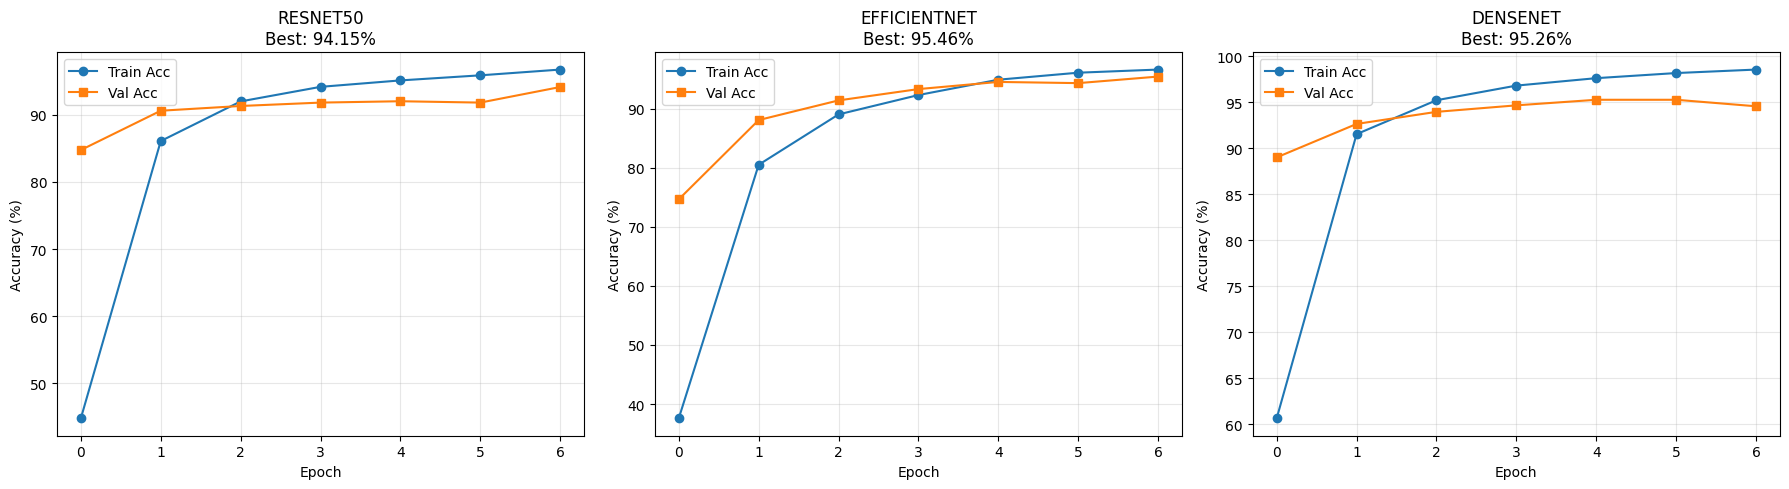

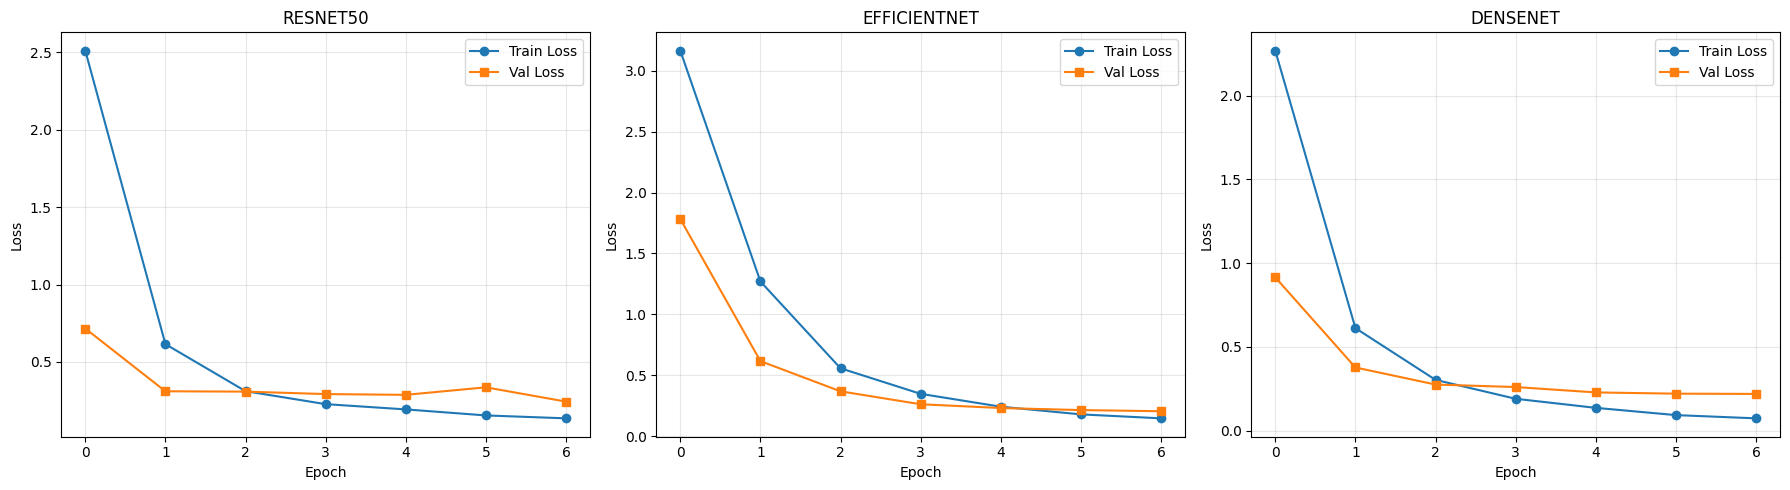


Лучшая модель: EFFICIENTNET с точностью 95.46%


Predicting: 100%|██████████| 8/8 [00:00<00:00, 11.98it/s]


In [21]:
# Список архитектур для экспериментов и словарь под результаты
models_to_try = ['resnet50', 'efficientnet', 'densenet']
results = {}

# Запускаем цикл обучения по всем выбранным моделям
for model_name in models_to_try:
    print("\n" + "="*60)
    print(f"ОБУЧЕНИЕ МОДЕЛИ: {model_name.upper()}")
    print("="*60)

    # Инициализируем текущую модель и закидываем её на видеокарту (CUDA)
    model = RSNAModel(num_classes=50, model_name=model_name)
    model = model.to(device)

    # Конфигурируем оптимизатор Adam и планировщик для снижения LR при плато по Loss
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

    # Переменная для лучшей точности и словарь для логирования метрик по эпохам
    best_val_acc = 0
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    # Тренируем модель 7 эпох
    for epoch in range(1, 8):
        # Шаг обучения на тренировочной выборке
        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer, criterion,
            epoch, device, log_wandb=False, verbose=False
        )

        # Проверка качества модели на валидационной выборке
        val_loss, val_acc = valid_one_epoch(
            model, valid_loader, criterion,
            epoch, device, log_wandb=False, verbose=False
        )

        # Обновляем планировщик на основе валидационного лосса
        scheduler.step(val_loss)

        # Сохраняем метрики текущей эпохи в историю
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        # Если точность выросла — обновляем максимум и сохраняем чекпоинт весов
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), f'best_{model_name}.pth')

    # Записываем финальные результаты модели в общий словарь
    results[model_name] = {
        'best_acc': best_val_acc,
        'history': history
    }

    print(f"{model_name.upper()} - Лучшая точность: {best_val_acc:.2f}%")

# Выводим в консоль итоговую таблицу сравнения всех моделей
print("\n" + "="*60)
print("СРАВНЕНИЕ МОДЕЛЕЙ")
print("="*60)

for model_name, data in results.items():
    print(f"{model_name.upper()}: {data['best_acc']:.2f}%")

# Строим графики точности (Accuracy) для всех трех моделей в один ряд
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (model_name, data) in enumerate(results.items()):
    ax = axes[idx]
    ax.plot(data['history']['train_acc'], label='Train Acc', marker='o')
    ax.plot(data['history']['val_acc'], label='Val Acc', marker='s')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy (%)')
    ax.set_title(f'{model_name.upper()}\nBest: {data["best_acc"]:.2f}%')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Строим аналогичные графики для функции потерь (Loss)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (model_name, data) in enumerate(results.items()):
    ax = axes[idx]
    ax.plot(data['history']['train_loss'], label='Train Loss', marker='o')
    ax.plot(data['history']['val_loss'], label='Val Loss', marker='s')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.set_title(f'{model_name.upper()}')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Автоматически находим модель с максимальной точностью на валидации
best_model = max(results.items(), key=lambda x: x[1]['best_acc'])
print(f"\nЛучшая модель: {best_model[0].upper()} с точностью {best_model[1]['best_acc']:.2f}%")

# Готовим тестовый датасет и загрузчик данных (батч-сайз 32)
test_dataset = MyDataset(TEST_DIR, transform=val_transform, is_train=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

# Создаем пустую модель-победитель и загружаем в нее сохраненные лучшие веса
model = RSNAModel(num_classes=50, model_name=best_model[0])
model.load_state_dict(torch.load(f'best_{best_model[0]}.pth'))
model = model.to(device)
model.eval()  # Переводим в режим инференса (отключаем dropout и batchnorm)

predictions = []
filenames = []

# Запускаем предсказание на тестовых данных без расчета градиентов
with torch.no_grad():
    for images, names in tqdm(test_loader, desc='Predicting'):
        images = images.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)  # Берем класс с максимальной вероятностью
        predictions.extend(predicted.cpu().numpy())  # Сохраняем прогнозы
        filenames.extend(names)  # Сохраняем имена файлов для отчета

# Маппинг индексов обратно в читаемые названия классов
idx_to_class = {idx: cls for cls, idx in train_data.dataset.class_to_idx.items()}


Вывод:

Все три модели обучились отлично, но лучшей стала EfficientNet.

Главные итогиПобедитель: EfficientNet набрала лучшую точность — 95.46%.

DenseNet отстала совсем чуть-чуть (95.26%),

а ResNet50 оказалась на третьем месте (94.15%).

Сходимость: На графиках видно, что EfficientNet и DenseNet учились стабильнее. У ResNet50 на последних эпохах валидационный лосс начал немного скакать вверх (намек на легкий оверфиттинг).

Скорость: Все модели вышли на плато уже к 4–5 эпохе, так что 7 эпох для этого эксперимента хватило с головой.

In [22]:
# Сохранение результата для каггл
submission = pd.DataFrame({
    'index': [filename[:-4] for filename in filenames],
    'label': [idx_to_class[idx][6:] for idx in predictions]
}).sort_values('index').reset_index(drop=True)
submission.to_csv('submission.csv', index=False)
print("\nСабмит сохранен как submission.csv")
print(submission.head())


Сабмит сохранен как submission.csv
  index label
0     0    14
1     1    40
2    10    38
3   100     1
4   101    48
